# 08 CatMouth and CatNose Specialist

This notebook trains a two-class ConvNeXt V2 Tiny model at 192 pixels to distinguish CatMouth from CatNose. Training uses 11,800 images, with 2,082 pair images reserved for validation. A fixed routing policy combines specialist predictions with the existing eight-class ensemble on eligible images. Evaluation measures both corrected predictions and newly introduced errors across the full validation set.

## 1 Setup and specialist configuration

In [ ]:
import os
USE_HF_SECRET = False
if USE_HF_SECRET:
    from kaggle_secrets import UserSecretsClient
    os.environ['HF_TOKEN'] = UserSecretsClient().get_secret('kaggle-assignment3')

from pathlib import Path
from io import BytesIO
import copy, hashlib, json, math, platform, random, shutil, time, zipfile
import numpy as np
import pandas as pd
from PIL import Image
import PIL
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as T
import torchvision.transforms.functional as TF
from torch.utils.data import Dataset, DataLoader
import timm
from timm.data import resolve_model_data_config
from sklearn.metrics import classification_report, confusion_matrix
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
from IPython.display import display

BASE = None
INPUT_PACK = None
RECOVERY_DIR = None  # Saved Notebook 08 run directory containing config.json and last.pth.
MODEL_NAME = 'convnextv2_tiny.fcmae_ft_in1k'
RUN_NAME = 'convnextv2_tiny_192_cat_mouth_nose_val1337_seed42'
OUT = Path('/kaggle/working/cat_mouth_nose_specialist')
RUN_DIR = OUT/RUN_NAME
TRAIN_SEED = 42
SPLIT_SEED = 1337
EPOCHS = 8
BATCH_SIZE = 64
NUM_WORKERS = 0
ALL_CLASSES = ['CatEye','CatFace','CatMouth','CatNose','DogEye','DogFace','DogMouth','DogNose']
CLASSES = ['CatMouth','CatNose']  # Binary output order; distinct from all-class references.
PAIR_INDICES = [2,3]
CLASS_TO_IDX = {c:i for i,c in enumerate(CLASSES)}
EXPECTED_LABEL_SHA = '94124e856786379a9c1e9c8c7ba4599a9f27fe8dc6ea4165dc4afc55024d41a3'
EXPECTED_SPLIT_HASH = '842af9ee7beb6fe8c85fd55163deeb15cf8a5c778506c075f987e9b9ed9889b6'
assert torch.cuda.is_available(), 'Enable a Kaggle GPU before starting this notebook.'
assert MODEL_NAME in timm.list_models(pretrained=True), 'Recorded pretrained model unavailable; review without upgrading packages automatically.'
device=torch.device('cuda')
versions=dict(python=platform.python_version(),torch=str(torch.__version__),
              torchvision=str(torchvision.__version__),timm=str(timm.__version__),
              numpy=str(np.__version__),pandas=str(pd.__version__),pillow=str(PIL.__version__))
probe=timm.create_model(MODEL_NAME,pretrained=False,num_classes=2)
resolved=resolve_model_data_config(probe)
assert np.allclose(resolved['mean'],[.485,.456,.406]) and np.allclose(resolved['std'],[.229,.224,.225]), 'Pretrained normalization changed; review before training.'
del probe
print('GPU:',torch.cuda.get_device_name(0),'| versions:',versions,flush=True)
print('One binary specialist: 192px, split 1337, eight epochs; no earlier training is repeated.',flush=True)


GPU: Tesla T4 | versions: {'python': '3.13.15', 'torch': '2.11.0+cu128', 'torchvision': '0.26.0+cu128', 'timm': '1.0.29', 'numpy': '2.1.3', 'pandas': '2.3.3', 'pillow': '12.3.0'}
One binary specialist: 192px, split 1337, eight epochs; no earlier training is repeated.


## 2 Input verification and fixed routing policy

The saved split, metadata and reference predictions are verified before training. The specialist uses 11,800 training images and 2,082 validation images from the CatMouth and CatNose classes. A fixed routing policy identifies eligible images using reference probabilities only, without consulting validation labels.

In [6]:
EXPECTED_PACK_MANIFEST_SHA = '570120d1b229b51a13abbfa837b50712d8b0f63d57301fa6398964ed07b5ca21'

EXPECTED_POLICY = {'pair_classes': ['CatMouth', 'CatNose'], 'pair_indices': [2, 3], 'minimum_pair_mass': 0.8, 'maximum_pair_conditional_confidence': 0.9, 'specialist_weight': 0.5, 'eligibility': 'Original reference top two classes must be exactly CatMouth and CatNose.', 'combination': 'Preserve pair probability mass; average reference conditional pair probabilities and specialist probabilities 50/50.', 'primary_view': 'tta', 'selection': 'Best clean binary validation accuracy; ordinary NLL tie breaker.', 'outside_route': 'All other rows and every non-pair probability remain unchanged.'}

def sha_bytes(raw): return hashlib.sha256(raw).hexdigest()

def sha_file(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for chunk in iter(lambda:f.read(4*1024*1024),b''): h.update(chunk)
    return h.hexdigest()

def check_matrix(p,rows,columns):
    assert p.shape==(rows,columns) and np.isfinite(p).all() and (p>=0).all() and (p<=1).all(), 'Invalid probability matrix.'
    assert np.allclose(p.sum(1),1,atol=2e-5,rtol=0), 'Probabilities do not sum to one.'

def check_probabilities(p,rows): check_matrix(p,rows,len(CLASSES))

def probability_metrics(y,p):
    assert len(y)>0
    return dict(errors=int((p.argmax(1)!=y).sum()),accuracy=float((p.argmax(1)==y).mean()),
                nll=float(-np.log(p[np.arange(len(y)),y].clip(1e-12,1)).mean()))

def read_pack(location):
    location=Path(location)
    if location.is_dir():
        def read(name): return (location/name).read_bytes()
    else:
        def read(name):
            with zipfile.ZipFile(location) as z: return z.read(name)
    manifest_raw=read('08_cat_pair_inputs_manifest.json')
    assert sha_bytes(manifest_raw)==EXPECTED_PACK_MANIFEST_SHA, 'Input pack differs from the checked experiment.'
    manifest=json.loads(manifest_raw);content={}
    for name,record in manifest['files'].items():
        raw=read(name)
        assert len(raw)==record['bytes'] and sha_bytes(raw)==record['sha256'], f'Input file failed verification: {name}'
        content[name]=raw
    return manifest,content,manifest_raw

def image_folder(base,kind):
    for path in [base/kind/kind,base/kind]:
        if (path/'00001.jpg').is_file(): return path
    raise FileNotFoundError(f'Missing {kind} images below {base}')

def validate_frames(content,official_labels):
    meta=pd.read_csv(BytesIO(content['train_metadata_clean.csv']))
    tr=pd.read_csv(BytesIO(content['train_split_1337.csv']))
    va=pd.read_csv(BytesIO(content['val_split_1337.csv']))
    assert len(meta)==63645 and meta.image_id.is_unique and meta.md5.is_unique
    assert len(tr)==54098 and len(va)==9547 and tr.image_id.is_unique and va.image_id.is_unique
    assert set(tr.image_id).isdisjoint(set(va.image_id))
    assert set(tr.image_id)|set(va.image_id)==set(meta.image_id)
    lookup=meta.set_index('image_id');official=official_labels.set_index('image_id')['class']
    assert np.array_equal(meta['class'],official.loc[meta.image_id])
    for frame in [tr,va]: assert np.array_equal(frame['class'],lookup.loc[frame.image_id,'class'])
    assert set(lookup.loc[tr.image_id,'md5']).isdisjoint(set(lookup.loc[va.image_id,'md5']))
    assert sha_bytes(va.image_id.to_numpy(dtype='<i8').tobytes())==EXPECTED_SPLIT_HASH
    pair_tr=tr[tr['class'].isin(CLASSES)].copy();pair_va=va[va['class'].isin(CLASSES)].copy()
    assert len(pair_tr)==11800 and len(pair_va)==2082
    assert pair_tr['class'].value_counts().to_dict()==dict(CatMouth=5900,CatNose=5900)
    assert pair_va['class'].value_counts().to_dict()==dict(CatMouth=1041,CatNose=1041)
    for frame in [pair_tr,pair_va]: frame['label']=frame['class'].map(CLASS_TO_IDX).astype('int64')
    full_va=va.copy();full_va['label']=full_va['class'].map({c:i for i,c in enumerate(ALL_CLASSES)}).astype('int64')
    return meta,tr,full_va,pair_tr,pair_va

def read_reference(raw,ids,truth=None):
    with np.load(BytesIO(raw),allow_pickle=False) as a:
        assert a['classes'].tolist()==ALL_CLASSES and np.array_equal(a['image_id'],ids)
        if truth is not None:
            assert str(a['split_hash'])==EXPECTED_SPLIT_HASH and np.array_equal(a['labels'],truth)
        else: assert 'labels' not in a.files
        p=a['probs'].astype('float64')
    check_matrix(p,len(ids),len(ALL_CLASSES));return p

def routing_mask(p):
    check_matrix(p,len(p),len(ALL_CLASSES))
    top=np.sort(np.argsort(p,axis=1,kind='stable')[:,-2:],axis=1)
    pair=p[:,PAIR_INDICES];mass=pair.sum(1)
    conditional=pair/np.maximum(mass[:,None],1e-12)
    return (top==np.array(PAIR_INDICES)).all(1)&(mass>=POLICY['minimum_pair_mass'])&(conditional.max(1)<=POLICY['maximum_pair_conditional_confidence'])

def route_probabilities(reference,specialist,routed):
    reference=np.asarray(reference,dtype='float64');specialist=np.asarray(specialist,dtype='float64')
    assert np.array_equal(routed,routing_mask(reference)), 'Routing must use the frozen reference predictions only.'
    check_probabilities(specialist,int(routed.sum()))
    out=reference.copy()
    if routed.any():
        pair=reference[np.ix_(routed,PAIR_INDICES)];mass=pair.sum(1,keepdims=True)
        mix=(1-POLICY['specialist_weight'])*(pair/mass)+POLICY['specialist_weight']*specialist
        out[np.ix_(routed,PAIR_INDICES)]=mass*mix
    check_matrix(out,len(reference),len(ALL_CLASSES))
    other=[i for i in range(len(ALL_CLASSES)) if i not in PAIR_INDICES]
    assert np.array_equal(out[~routed],reference[~routed])
    assert np.array_equal(out[:,other],reference[:,other])
    assert np.allclose(out[:,PAIR_INDICES].sum(1),reference[:,PAIR_INDICES].sum(1),atol=1e-12,rtol=0)
    assert np.array_equal(out.argmax(1)[~routed],reference.argmax(1)[~routed])
    assert np.isin(out.argmax(1)[routed],PAIR_INDICES).all()
    return out

if INPUT_PACK is None:
    choices=[p.parent for p in Path('/kaggle/input').rglob('08_cat_pair_inputs_manifest.json')]
    if not choices: choices=list(Path('/kaggle/input').rglob('08_cat_pair_inputs.zip'))
    assert len(choices)==1, f'Attach the private 08_cat_pair_inputs pack or set INPUT_PACK explicitly. Found: {choices}'
    INPUT_PACK=choices[0]
pack,pack_files,pack_manifest_raw=read_pack(INPUT_PACK)
POLICY=pack['routing_policy']
assert POLICY==EXPECTED_POLICY, 'Routing policy differs from the declaration.'
if BASE is None:
    choices=[]
    for path in Path('/kaggle/input').rglob('train_labels.csv'):
        if not (path.parent/'sample_submission.csv').is_file(): continue
        try: image_folder(path.parent,'train');image_folder(path.parent,'test')
        except FileNotFoundError: continue
        choices.append(path.parent)
    assert len(choices)==1, f'Attach Competition or set BASE explicitly. Found: {choices}'
    BASE=choices[0]
BASE=Path(BASE);TRAIN_DIR=image_folder(BASE,'train');TEST_DIR=image_folder(BASE,'test')
assert sha_file(BASE/'train_labels.csv')==EXPECTED_LABEL_SHA
official_labels=pd.read_csv(BASE/'train_labels.csv');sample=pd.read_csv(BASE/'sample_submission.csv')
assert official_labels.columns.tolist()==sample.columns.tolist()==['image_id','class']
assert len(official_labels)==63660 and official_labels.image_id.is_unique
assert len(sample)==29443 and sample.image_id.is_unique and not sample.image_id.isna().any()
meta,full_train_df,full_val_df,train_df,val_df=validate_frames(pack_files,official_labels)
val_ids=val_df.image_id.to_numpy(dtype='int64');y=val_df.label.to_numpy(dtype='int64')
full_val_ids=full_val_df.image_id.to_numpy(dtype='int64');full_y=full_val_df.label.to_numpy(dtype='int64')
test_ids=sample.image_id.to_numpy(dtype='int64')
assert sha_bytes(test_ids.astype('<i8').tobytes())==pack['test_id_order_sha256']
reference_val=read_reference(pack_files['reference_validation_proxy.npz'],full_val_ids,full_y)
rebuild={}
for name,view in [('control','clean'),('geometry','clean'),('v2','tta')]:
    cfg=json.loads(pack_files[f'reference_{name}_config.json'])
    assert cfg['split_hash']==EXPECTED_SPLIT_HASH and not cfg['full_data']
    rebuild[name]=read_reference(pack_files[f'reference_{name}_val_{view}.npz'],full_val_ids,full_y)
    assert probability_metrics(full_y,rebuild[name])['errors']==pack['reference_errors'][f'{name}_{view}']
direct=.75*(.75*rebuild['control']+.25*rebuild['geometry'])+.25*rebuild['v2']
assert np.max(np.abs(direct-reference_val))<2e-7 and np.array_equal(direct.argmax(1),reference_val.argmax(1))
assert probability_metrics(full_y,reference_val)['errors']==23
reference_test=read_reference(pack_files['reference_best_test.npz'],test_ids)
best_csv=pd.read_csv(BytesIO(pack_files['reference_best_submission.csv']))
assert sha_bytes(pack_files['reference_best_submission.csv'])==pack['best_submission_sha256']
assert np.array_equal(best_csv.image_id,test_ids)
assert np.array_equal(best_csv['class'],np.array(ALL_CLASSES)[reference_test.argmax(1)])
val_route=routing_mask(reference_val);test_route=routing_mask(reference_test)
assert int(val_route.sum())==pack['routing_counts']['validation']==39
assert int(test_route.sum())==pack['routing_counts']['test']==312
for r in meta.sample(n=32,random_state=42).itertuples(index=False):
    assert hashlib.md5((TRAIN_DIR/f'{int(r.image_id):05d}.jpg').read_bytes()).hexdigest()==r.md5
print('Verified pair training:',len(train_df),'| pair validation:',len(val_df),'| full validation:',len(full_val_df),flush=True)
print('Fixed route:',int(val_route.sum()),'validation /',int(test_route.sum()),'test. Public outcome unknown.',flush=True)


Verified pair training: 11800 | pair validation: 2082 | full validation: 9547
Fixed route: 39 validation / 312 test. Public outcome unknown.


## 3 Preprocessing and image loading

Images are resized to 192 × 192 pixels and normalised using ImageNet statistics. Training uses downscaling, geometry, horizontal-flip and colour augmentation. Validation and test images use deterministic preprocessing, with flip averaging evaluated separately.

In [8]:
def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed); random.seed(worker_seed)

class RandomDownscale:
    def __init__(self, p=.3): self.p=p
    def __call__(self, img):
        if random.random() < self.p:
            target=random.randint(16,48); short=min(img.size)
            if short > target:
                scale=target/short
                img=img.resize((max(1,round(img.width*scale)), max(1,round(img.height*scale))),
                               Image.Resampling.BILINEAR)
        return img

class AxisPad:
    def __init__(self, p=.5, max_fraction=.15, fixed=None):
        self.p, self.max_fraction, self.fixed = p, max_fraction, fixed
    def __call__(self, img):
        if self.fixed is None:
            if random.random() >= self.p: return img
            fx=random.uniform(0,self.max_fraction)
            fy=random.uniform(0,self.max_fraction)
        else:
            fx,fy=self.fixed
        w,h=img.size
        px,py=round(w*fx),round(h*fy)
        # This runs after square resizing: padding is always smaller than either side.
        return TF.pad(img, [px,py,px,py], padding_mode='reflect')

def transforms_for(cfg, training=False, stress=None):
    s=cfg['size']; ops=[]
    if training: ops.append(RandomDownscale(cfg['downscale_p']))
    ops.append(T.Resize((s,s), interpolation=T.InterpolationMode.BILINEAR, antialias=True))
    if training and cfg['geometry']:
        ops.extend([AxisPad(), T.Resize((s,s), antialias=True)])
    if stress:
        fixed={'wide':(0,.15), 'tall':(.15,0)}[stress]
        ops.extend([AxisPad(fixed=fixed), T.Resize((s,s), antialias=True)])
    if training:
        ops.extend([T.RandomHorizontalFlip(.5),
                    T.RandomAffine(degrees=10, translate=(.05,.05), scale=(.9,1.1)),
                    T.ColorJitter(brightness=.3, contrast=.3, saturation=.2)])
    ops.extend([T.ToTensor(), T.Normalize(cfg['mean'],cfg['std'])])
    return T.Compose(ops)

class Images(Dataset):
    def __init__(self, frame, folder, transform):
        self.frame=frame.reset_index(drop=True); self.folder=folder; self.transform=transform
    def __len__(self): return len(self.frame)
    def __getitem__(self,i):
        r=self.frame.iloc[i]; image_id=int(r['image_id'])
        with Image.open(self.folder/f'{image_id:05d}.jpg') as im:
            x=self.transform(im.convert('RGB'))
        y=int(r['label']) if 'label' in self.frame.columns else -1
        return x,y,image_id

PIPELINE_SOURCE_SHA = 'f04bbb60499628ed7827606f874d9707ddbee854a8f0400e51de17da26150be1'


## 4 Training configuration and saved-run checks

The specialist uses a pretrained ConvNeXt V2 Tiny backbone with a two-class head. Training follows an eight-epoch schedule using AdamW and label-smoothed cross-entropy. Configuration and provenance checks prevent incompatible saved runs from being reused.

In [9]:
CFG=dict(model=MODEL_NAME,size=192,geometry=True,epochs=EPOCHS,batch_size=BATCH_SIZE,
         lr=3e-4,weight_decay=.05,label_smoothing=.1,downscale_p=.3,
         mean=list(map(float,resolved['mean'])),std=list(map(float,resolved['std'])),
         split_seed=SPLIT_SEED,train_seed=TRAIN_SEED,full_data=False,classes=CLASSES,
         all_classes=ALL_CLASSES,training_images=len(train_df),pair_validation_images=len(val_df),
         label_sha256=EXPECTED_LABEL_SHA,split_hash=EXPECTED_SPLIT_HASH,
         input_pack_manifest_sha256=EXPECTED_PACK_MANIFEST_SHA,
         experiment_version='08-cat-pair-specialist-v1',pipeline_source_sha256=PIPELINE_SOURCE_SHA,
         routing_policy=POLICY,
         augmentation=dict(downscale_p=.3,downscale_short_side=[16,48],geometry_p=.5,
                           geometry_max_fraction_per_side=.15,horizontal_flip_p=.5,
                           affine_degrees=10,translation_per_axis=.05,scale=[.9,1.1],
                           brightness=.3,contrast=.3,saturation=.2),
         resize_interpolation='bilinear',antialias=True,num_workers=NUM_WORKERS,
         persistent_workers=False,drop_last=False,amp='float16',versions=versions)
CFG_SHA=sha_bytes(json.dumps(CFG,sort_keys=True).encode())
def atomic_json(path,data):
    path=Path(path);temp=path.with_name(path.name+'.tmp')
    temp.write_text(json.dumps(data,indent=2)+'\n');os.replace(temp,path)

def atomic_torch(path,data):
    path=Path(path);temp=path.with_name(path.name+'.tmp')
    torch.save(data,temp);os.replace(temp,path)

def make_loader(frame,folder,training=False):
    generator=torch.Generator().manual_seed(TRAIN_SEED)
    loader=DataLoader(Images(frame,folder,transforms_for(CFG,training=training)),
                      batch_size=BATCH_SIZE,shuffle=training,drop_last=False,
                      num_workers=NUM_WORKERS,pin_memory=True,persistent_workers=False,
                      worker_init_fn=seed_worker,generator=generator)
    return loader,generator

def current_random_state(generator):
    n=np.random.get_state()
    return dict(python=random.getstate(),numpy=(n[0],n[1].tolist(),n[2],n[3],n[4]),
                torch=torch.get_rng_state(),cuda=torch.cuda.get_rng_state(device),
                loader=generator.get_state())

def restore_random_state(state,generator):
    random.setstate(state['python'])
    n=state['numpy'];np.random.set_state((n[0],np.array(n[1],dtype=np.uint32),n[2],n[3],n[4]))
    torch.set_rng_state(state['torch']);torch.cuda.set_rng_state(state['cuda'],device)
    generator.set_state(state['loader'])

def schedule_factor(step,warmup_steps,total_steps):
    if step<warmup_steps: return (step+1)/warmup_steps
    progress=(step-warmup_steps)/max(1,total_steps-warmup_steps)
    return .5*(1+math.cos(math.pi*min(progress,1)))

@torch.inference_mode()
def predict_views(model,loader,description,flip=False):
    model.eval();clean=[];tta=[];ys=[];ids=[]
    for x,target,image_id in tqdm(loader,desc=description,leave=True):
        x=x.to(device,non_blocking=True)
        with torch.autocast('cuda',dtype=torch.float16):
            logits=model(x)
        p=torch.softmax(logits.float(),dim=1)
        clean.append(p.cpu().numpy())
        if flip:
            with torch.autocast('cuda',dtype=torch.float16):
                flipped_logits=model(x.flip(-1))
            q=torch.softmax(flipped_logits.float(),dim=1)
            tta.append(((p+q)/2).cpu().numpy())
        ys.append(target.numpy());ids.append(image_id.numpy())
    return np.concatenate(clean),None if not flip else np.concatenate(tta),np.concatenate(ys),np.concatenate(ids)

def restore_saved_run():
    if (RUN_DIR/'config.json').exists():
        assert json.loads((RUN_DIR/'config.json').read_text())==dict(config_sha256=CFG_SHA,config=CFG), 'Existing run settings differ; they will not be overwritten.'
        if (RUN_DIR/'last.pth').exists() or (RUN_DIR/'training_complete.json').exists(): return
    existing=[p for p in RUN_DIR.glob('*') if p.suffix!='.tmp' and p.name!='config.json'] if RUN_DIR.exists() else []
    assert not existing, 'This local run directory lacks its config. Preserve it and review before restarting.'
    if RECOVERY_DIR is not None:
        choices=[Path(RECOVERY_DIR)]
    else:
        choices=[p.parent for p in Path('/kaggle/input').rglob('config.json') if p.parent.name==RUN_NAME]
    assert len(choices)<=1, f'Multiple saved Notebook 08 runs found. Set RECOVERY_DIR explicitly: {choices}'
    if choices:
        source=choices[0]
        record=json.loads((source/'config.json').read_text())
        assert record['config_sha256']==CFG_SHA, 'Saved run settings/environment differ; preserve that run and review the config.'
        assert (source/'last.pth').is_file() or (source/'training_complete.json').is_file(), 'Saved run has no recoverable epoch checkpoint.'
        shutil.copytree(source,RUN_DIR,dirs_exist_ok=True)
        print('Restored saved Notebook 08 files from:',source,flush=True)

restore_saved_run()
RUN_DIR.mkdir(parents=True,exist_ok=True)
record=dict(config_sha256=CFG_SHA,config=CFG)
if (RUN_DIR/'config.json').exists():
    assert json.loads((RUN_DIR/'config.json').read_text())==record, 'Existing run settings differ and will not be overwritten.'
else: atomic_json(RUN_DIR/'config.json',record)
for name,frame in [('pair_train_split_1337.csv',train_df),('pair_val_split_1337.csv',val_df),('full_val_split_1337.csv',full_val_df)]:
    raw=frame.to_csv(index=False,lineterminator='\n').encode();path=OUT/name
    if path.exists(): assert path.read_bytes()==raw
    else: path.write_bytes(raw)
atomic_json(OUT/'input_pack_manifest.json',pack)
atomic_json(OUT/'routing_policy.json',POLICY)
print('Specialist settings saved. Normalization:',CFG['mean'],CFG['std'],'| workers:',NUM_WORKERS,flush=True)


Specialist settings saved. Normalization: [0.485, 0.456, 0.406] [0.229, 0.224, 0.225] | workers: 0


## 5 Specialist training and checkpoint selection

The checkpoint is selected by clean binary validation accuracy, with ordinary NLL as the tie breaker. Selection uses only the 2,082 pair-validation images; the full eight-class routing comparison is evaluated afterward. Training states are saved after each completed epoch to support recovery.

model.safetensors: reconstructing file:   0%|          |  0.00B /  115MB            

model.safetensors: downloading bytes:           |  0.00B            

START: one CatMouth/CatNose specialist, 11,800 training images, eight epochs. Initial weight download may take time.


Cat-pair specialist epoch 1/8:   0%|          | 0/185 [00:00<?, ?it/s]

Clean validation epoch 1/8:   0%|          | 0/33 [00:00<?, ?it/s]

...

Clean validation epoch 7/8:   0%|          | 0/33 [00:00<?, ?it/s]

{'epoch': 7, 'train_loss': 0.20288160128108526, 'train_acc': 0.9977118644067796, 'val_acc': 0.9903938520653218, 'val_nll': 0.07325568050146103, 'val_errors': 20, 'skipped_updates': 3, 'successful_updates': 1292, 'seconds': 144.6}


Cat-pair specialist epoch 8/8:   0%|          | 0/185 [00:00<?, ?it/s]

Clean validation epoch 8/8:   0%|          | 0/33 [00:00<?, ?it/s]

{'epoch': 8, 'train_loss': 0.20251883506774904, 'train_acc': 0.998135593220339, 'val_acc': 0.9913544668587896, 'val_nll': 0.0710010826587677, 'val_errors': 18, 'skipped_updates': 3, 'successful_updates': 1477, 'seconds': 144.8}
Training complete. Loaded best checkpoint epoch 8


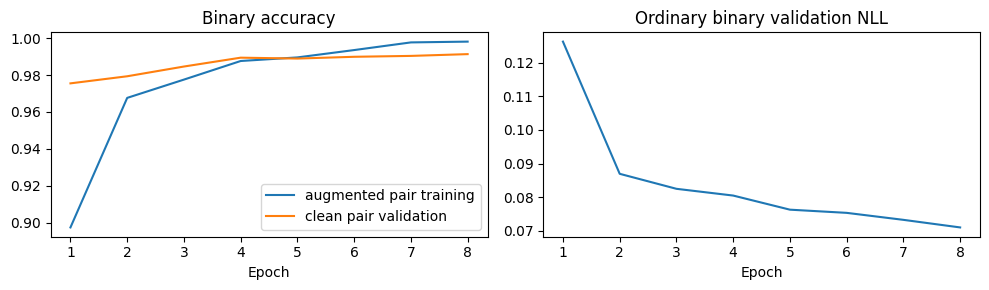

In [10]:
def train_or_resume():
    seed_all(TRAIN_SEED)
    completed=RUN_DIR/'training_complete.json';last_path=RUN_DIR/'last.pth';best_path=RUN_DIR/'best.pth'
    if completed.exists():
        done=json.loads(completed.read_text())
        assert done['config_sha256']==CFG_SHA and done['completed_epochs']==EPOCHS
        assert sha_file(best_path)==done['best_sha256']
        assert sha_file(RUN_DIR/'history.csv')==done['history_sha256']
        saved=torch.load(best_path,map_location='cpu',weights_only=True)
        assert saved['config_sha256']==CFG_SHA and saved['config']==CFG
        model=timm.create_model(MODEL_NAME,pretrained=False,num_classes=len(CLASSES)).to(device)
        model.load_state_dict(saved['model'])
        history=pd.read_csv(RUN_DIR/'history.csv')
        assert history.epoch.tolist()==list(range(1,EPOCHS+1))
        print('Reused completed training. Selected epoch:',saved['epoch'],flush=True)
        return model,history
    assert last_path.exists() or not (best_path.exists() or (RUN_DIR/'history.csv').exists()), 'A partial run has no last.pth; preserve it for review before retraining.'
    resume=last_path.exists()
    model=timm.create_model(MODEL_NAME,pretrained=not resume,num_classes=len(CLASSES)).to(device)
    train_loader,train_generator=make_loader(train_df,TRAIN_DIR,training=True)
    val_loader,_=make_loader(val_df,TRAIN_DIR)
    opt=torch.optim.AdamW(model.parameters(),lr=CFG['lr'],weight_decay=CFG['weight_decay'])
    steps=len(train_loader);total=EPOCHS*steps
    scheduler=torch.optim.lr_scheduler.LambdaLR(opt,lambda step:schedule_factor(step,steps,total))
    scaler=torch.amp.GradScaler('cuda')
    criterion=nn.CrossEntropyLoss(label_smoothing=CFG['label_smoothing'])
    history=[];best_rank=(-1.,-float('inf'));best_epoch=None;best_state=None;best_metrics=None
    skipped=0;updates=0;start_epoch=1
    if resume:
        saved=torch.load(last_path,map_location='cpu',weights_only=True)
        assert saved['config_sha256']==CFG_SHA and saved['config']==CFG
        assert 1<=saved['epoch']<=EPOCHS
        model.load_state_dict(saved['model']);opt.load_state_dict(saved['optimizer'])
        scheduler.load_state_dict(saved['scheduler']);scaler.load_state_dict(saved['scaler'])
        history=saved['history'];best_rank=tuple(saved['best_rank']);best_epoch=saved['best_epoch']
        best_state=saved['best_model'];best_metrics=saved['best_metrics']
        assert [r['epoch'] for r in history]==list(range(1,saved['epoch']+1))
        skipped=saved['skipped_updates'];updates=saved['successful_updates'];start_epoch=saved['epoch']+1
        restore_random_state(saved['random_state'],train_generator)
        del saved
        print('Resuming after completed epoch',start_epoch-1,'of',EPOCHS,flush=True)
    else:
        print('START: one CatMouth/CatNose specialist, 11,800 training images, eight epochs. Initial weight download may take time.',flush=True)
    for epoch in range(start_epoch,EPOCHS+1):
        start=time.perf_counter();model.train();loss_sum=0.;correct=0;n=0
        bar=tqdm(train_loader,desc=f'Cat-pair specialist epoch {epoch}/{EPOCHS}',leave=True)
        for x,target,_ in bar:
            x=x.to(device,non_blocking=True);target=target.to(device,non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast('cuda',dtype=torch.float16):
                logits=model(x);loss=criterion(logits,target)
            assert torch.isfinite(loss).item(), 'Non-finite training loss. Last completed epoch remains saved.'
            before=scaler.get_scale()
            scaler.scale(loss).backward();scaler.step(opt);scaler.update()
            if scaler.get_scale()>=before: scheduler.step();updates+=1
            else: skipped+=1
            loss_sum+=float(loss.item())*len(target)
            correct+=int((logits.argmax(1)==target).sum().item());n+=len(target)
            bar.set_postfix(loss=f'{loss_sum/n:.4f}',lr=f'{opt.param_groups[0]["lr"]:.2g}')
        p,_,target,ids=predict_views(model,val_loader,f'Clean validation epoch {epoch}/{EPOCHS}')
        assert np.array_equal(ids,val_ids) and np.array_equal(target,y)
        check_probabilities(p,len(y));m=probability_metrics(y,p)
        rank=(m['accuracy'],-m['nll'])
        current_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        if rank>best_rank:
            best_rank=rank;best_epoch=epoch;best_state=current_state;best_metrics=m
        row=dict(epoch=epoch,train_loss=loss_sum/n,train_acc=correct/n,val_acc=m['accuracy'],
                 val_nll=m['nll'],val_errors=m['errors'],skipped_updates=skipped,
                 successful_updates=updates,seconds=round(time.perf_counter()-start,1))
        history.append(row)
        payload=dict(config_sha256=CFG_SHA,config=CFG,epoch=epoch,model=current_state,
                     optimizer=opt.state_dict(),scheduler=scheduler.state_dict(),scaler=scaler.state_dict(),
                     history=history,best_model=best_state,best_rank=best_rank,best_epoch=best_epoch,
                     best_metrics=best_metrics,skipped_updates=skipped,successful_updates=updates,
                     random_state=current_random_state(train_generator))
        # This is the authoritative epoch commit. CSV/best files can be rebuilt from it.
        atomic_torch(last_path,payload)
        del payload,current_state
        pd.DataFrame(history).to_csv(RUN_DIR/'history.csv',index=False)
        atomic_torch(best_path,dict(model=best_state,config=CFG,config_sha256=CFG_SHA,
                                   epoch=best_epoch,validation=best_metrics))
        print(row,flush=True)
    assert len(history)==EPOCHS and best_state is not None
    pd.DataFrame(history).to_csv(RUN_DIR/'history.csv',index=False)
    atomic_torch(best_path,dict(model=best_state,config=CFG,config_sha256=CFG_SHA,
                               epoch=best_epoch,validation=best_metrics))
    atomic_json(completed,dict(config_sha256=CFG_SHA,completed_epochs=EPOCHS,best_epoch=best_epoch,
                               best_sha256=sha_file(best_path),history_sha256=sha_file(RUN_DIR/'history.csv')))
    model.load_state_dict(best_state)
    del train_loader,val_loader,opt,scheduler,scaler,best_state
    torch.cuda.empty_cache()
    print('Training complete. Loaded best checkpoint epoch',best_epoch,flush=True)
    return model,pd.DataFrame(history)

model,history=train_or_resume()
fig,axs=plt.subplots(1,2,figsize=(10,3))
axs[0].plot(history.epoch,history.train_acc,label='augmented pair training')
axs[0].plot(history.epoch,history.val_acc,label='clean pair validation')
axs[0].set(title='Binary accuracy',xlabel='Epoch');axs[0].legend()
axs[1].plot(history.epoch,history.val_nll)
axs[1].set(title='Ordinary binary validation NLL',xlabel='Epoch')
plt.tight_layout();fig.savefig(RUN_DIR/'learning_curves.png',dpi=160);plt.show();plt.close(fig)


## 6 Training checkpoint backup

The completed training configuration and checkpoints are packaged into a separate backup before routing evaluation. Archive integrity is checked to confirm that the saved files can be read without corruption.

In [11]:
from pathlib import Path
import zipfile

specialist_root = Path("/kaggle/working/cat_mouth_nose_specialist")
specialist_run = specialist_root / (
    "convnextv2_tiny_192_cat_mouth_nose_val1337_seed42"
)

required = ["config.json", "best.pth", "last.pth", "training_complete.json"]
missing = [name for name in required if not (specialist_run / name).is_file()]
if missing:
    raise FileNotFoundError(f"Missing files: {missing}")

training_backup = Path(
    "/kaggle/working/cat_mouth_nose_specialist_training_backup.zip"
)

with zipfile.ZipFile(training_backup, "w", zipfile.ZIP_STORED) as archive:
    for path in sorted(specialist_root.rglob("*")):
        if path.is_file():
            archive.write(path, path.relative_to(specialist_root.parent))

with zipfile.ZipFile(training_backup) as archive:
    damaged = archive.testzip()
    if damaged is not None:
        raise RuntimeError(f"Backup check failed: {damaged}")

print("Backup verified:", training_backup)
print(f"Size: {training_backup.stat().st_size / 1024**2:.1f} MiB")

Backup verified: /kaggle/working/cat_mouth_nose_specialist_training_backup.zip
Size: 426.0 MiB


## 7 Specialist routing and validation comparison

For eligible images, reference and specialist conditional probabilities for CatMouth and CatNose are averaged equally. Their combined probability mass and the other six class probabilities are preserved. Evaluation counts corrected predictions and new errors across the full holdout and relevant subgroups.

In [12]:
# Corrected routing: remove tiny float32 rounding differences.
def route_probabilities(reference, specialist, routed):
    reference = np.asarray(reference, dtype="float64")
    specialist = np.asarray(specialist, dtype="float64")

    assert np.array_equal(routed, routing_mask(reference))
    check_probabilities(specialist, int(routed.sum()))

    out = reference.copy()

    if routed.any():
        specialist = specialist / specialist.sum(axis=1, keepdims=True)

        pair = reference[np.ix_(routed, PAIR_INDICES)]
        mass = pair.sum(axis=1, keepdims=True)

        mix = (
            (1 - POLICY["specialist_weight"]) * (pair / mass)
            + POLICY["specialist_weight"] * specialist
        )
        mix = mix / mix.sum(axis=1, keepdims=True)

        out[np.ix_(routed, PAIR_INDICES)] = mass * mix

    check_matrix(out, len(reference), len(ALL_CLASSES))

    other = [
        i for i in range(len(ALL_CLASSES))
        if i not in PAIR_INDICES
    ]

    assert np.array_equal(out[~routed], reference[~routed])
    assert np.array_equal(out[:, other], reference[:, other])
    assert np.allclose(
        out[:, PAIR_INDICES].sum(axis=1),
        reference[:, PAIR_INDICES].sum(axis=1),
        atol=1e-12,
        rtol=0,
    )
    assert np.array_equal(
        out.argmax(axis=1)[~routed],
        reference.argmax(axis=1)[~routed],
    )
    assert np.isin(out.argmax(axis=1)[routed], PAIR_INDICES).all()

    return out


BEST_SHA = sha_file(RUN_DIR / "best.pth")


def checked_binary_prediction(path, ids, truth8=None):
    with np.load(path, allow_pickle=False) as a:
        assert a["classes"].tolist() == CLASSES
        assert np.array_equal(a["image_id"], ids)
        assert str(a["config_sha256"]) == CFG_SHA
        assert str(a["checkpoint_sha256"]) == BEST_SHA
        assert str(a["split_hash"]) == EXPECTED_SPLIT_HASH

        if truth8 is None:
            assert "true_class_8" not in a.files
            assert "labels" not in a.files
        else:
            assert a["truth_class_order"].tolist() == ALL_CLASSES
            assert np.array_equal(a["true_class_8"], truth8)

        p = a["probs"].copy()

    check_probabilities(p, len(ids))
    return p


def save_binary_prediction(path, p, ids, truth8=None):
    check_probabilities(p, len(ids))
    temp = path.with_name(path.name + ".tmp")

    data = dict(
        probs=p.astype("float32"),
        image_id=np.asarray(ids, dtype="int64"),
        classes=np.array(CLASSES),
        config_sha256=np.array(CFG_SHA),
        checkpoint_sha256=np.array(BEST_SHA),
        split_hash=np.array(EXPECTED_SPLIT_HASH),
    )

    if truth8 is not None:
        data.update(
            true_class_8=np.asarray(truth8, dtype="int64"),
            truth_class_order=np.array(ALL_CLASSES),
        )

    with temp.open("wb") as f:
        np.savez_compressed(f, **data)

    os.replace(temp, path)
    return checked_binary_prediction(path, ids, truth8)


def binary_predictions_for(frame, folder, prefix, truth8=None):
    ids = frame.image_id.to_numpy(dtype="int64")
    paths = {
        view: RUN_DIR / f"{prefix}_binary_{view}.npz"
        for view in ["clean", "tta"]
    }

    found = {
        view: checked_binary_prediction(path, ids, truth8)
        for view, path in paths.items()
        if path.exists()
    }

    if len(found) == 2:
        print(
            "Reused verified specialist predictions:",
            prefix,
            flush=True,
        )
        return found

    if len(ids) == 0:
        clean = np.empty((0, 2), dtype="float32")
        tta = clean.copy()
    else:
        loader, _ = make_loader(frame, folder)
        clean, tta, _, pred_ids = predict_views(
            model,
            loader,
            f"{prefix}: specialist original + flip",
            flip=True,
        )
        assert np.array_equal(pred_ids, ids)
        del loader

    for view, p in [("clean", clean), ("tta", tta)]:
        if view not in found:
            found[view] = save_binary_prediction(
                paths[view], p, ids, truth8
            )

    return found


def save_routed_prediction(path, p, ids, reference_raw, truth8=None):
    check_matrix(p, len(ids), len(ALL_CLASSES))
    temp = path.with_name(path.name + ".tmp")

    data = dict(
        probs=p,
        image_id=np.asarray(ids, dtype="int64"),
        classes=np.array(ALL_CLASSES),
        config_sha256=np.array(CFG_SHA),
        checkpoint_sha256=np.array(BEST_SHA),
        split_hash=np.array(EXPECTED_SPLIT_HASH),
        reference_sha256=np.array(sha_bytes(reference_raw)),
        routing_policy_sha256=np.array(
            sha_bytes(json.dumps(POLICY, sort_keys=True).encode())
        ),
    )

    if truth8 is not None:
        data["labels"] = np.asarray(truth8, dtype="int64")

    with temp.open("wb") as f:
        np.savez_compressed(f, **data)

    os.replace(temp, path)

    with np.load(path, allow_pickle=False) as a:
        assert np.array_equal(a["probs"], p)
        assert np.array_equal(a["image_id"], ids)
        assert a["classes"].tolist() == ALL_CLASSES

        if truth8 is None:
            assert "labels" not in a.files
        else:
            assert np.array_equal(a["labels"], truth8)


def comparison_row(view, reference, candidate, truth, mask, group):
    if not mask.any():
        return dict(
            view=view,
            group=group,
            images=0,
            before_errors=None,
            after_errors=None,
            fixed=0,
            broken=0,
            changed=0,
            before_nll=None,
            after_nll=None,
        )

    old = reference.argmax(axis=1)
    new = candidate.argmax(axis=1)

    before = probability_metrics(truth[mask], reference[mask])
    after = probability_metrics(truth[mask], candidate[mask])

    return dict(
        view=view,
        group=group,
        images=int(mask.sum()),
        before_errors=before["errors"],
        after_errors=after["errors"],
        fixed=int(((old != truth) & (new == truth) & mask).sum()),
        broken=int(((old == truth) & (new != truth) & mask).sum()),
        changed=int(((old != new) & mask).sum()),
        before_nll=before["nll"],
        after_nll=after["nll"],
    )


# Reuse the completed validation prediction files.
val_binary = binary_predictions_for(
    full_val_df, TRAIN_DIR, "val", truth8=full_y
)

pair_mask = np.isin(full_y, PAIR_INDICES)
pair_truth = np.array([
    0 if c == 2 else 1
    for c in full_y[pair_mask]
])

short = (
    meta.set_index("image_id")
    .loc[full_val_ids, ["width", "height"]]
    .min(axis=1)
    .to_numpy()
    < 32
)

groups = {
    "all_validation": np.ones(len(full_y), dtype=bool),
    "routed": val_route,
    "true_cat_pair": pair_mask,
    "short_side_under32": short,
    "short_side32plus": ~short,
}

rows = []
pair_rows = []
routed_val = {}

for view in ["clean", "tta"]:
    routed_val[view] = route_probabilities(
        reference_val,
        val_binary[view][val_route],
        val_route,
    )

    save_routed_prediction(
        RUN_DIR / f"val_routed_{view}.npz",
        routed_val[view],
        full_val_ids,
        pack_files["reference_validation_proxy.npz"],
        full_y,
    )

    pair_rows.append(dict(
        view=view,
        images=int(pair_mask.sum()),
        **probability_metrics(
            pair_truth,
            val_binary[view][pair_mask],
        ),
    ))

    for group, mask in groups.items():
        rows.append(comparison_row(
            view,
            reference_val,
            routed_val[view],
            full_y,
            mask,
            group,
        ))

comparison = pd.DataFrame(rows)
comparison.to_csv(
    OUT / "validation_comparison.csv",
    index=False,
)

pd.DataFrame(pair_rows).to_csv(
    OUT / "binary_pair_metrics.csv",
    index=False,
)

display(pd.DataFrame(pair_rows))
display(comparison)

primary = next(
    r for r in rows
    if r["view"] == "tta" and r["group"] == "all_validation"
)

primary_pair = next(
    r for r in rows
    if r["view"] == "tta" and r["group"] == "true_cat_pair"
)

preliminary_pass = bool(
    primary["after_errors"] < primary["before_errors"]
    and primary["fixed"] > primary["broken"]
)

atomic_json(
    OUT / "validation_review.json",
    dict(
        primary_view="tta",
        all_class_comparison=primary,
        pair_comparison=primary_pair,
        preliminary_development_pass=preliminary_pass,
        automatic_submission=False,
        note=(
            "Development diagnostic only. Review broken predictions, "
            "pair/subgroup counts and NLL before choosing a public test. "
            "No independent full-winning-blend holdout score exists."
        ),
    ),
)

pred = routed_val["tta"].argmax(axis=1)
old = reference_val.argmax(axis=1)

changes = pd.DataFrame(dict(
    image_id=full_val_ids,
    true_class=np.array(ALL_CLASSES)[full_y],
    previous_class=np.array(ALL_CLASSES)[old],
    specialist_routed_class=np.array(ALL_CLASSES)[pred],
    routed=val_route,
    fixed=(old != full_y) & (pred == full_y),
    broken=(old == full_y) & (pred != full_y),
))

changes[old != pred].to_csv(
    OUT / "validation_changed_predictions.csv",
    index=False,
)

pd.DataFrame(
    confusion_matrix(full_y, pred, labels=range(8)),
    index=ALL_CLASSES,
    columns=ALL_CLASSES,
).to_csv(OUT / "confusion_matrix_routed_tta.csv")

(OUT / "classification_report_routed_tta.txt").write_text(
    classification_report(
        full_y,
        pred,
        labels=range(8),
        target_names=ALL_CLASSES,
        digits=5,
        zero_division=0,
    )
)

print(
    "PRIMARY TTA:",
    primary,
    "| preliminary development pass:",
    preliminary_pass,
    flush=True,
)

print(
    "This does not establish an improvement over "
    "the exact 0.9806 public ensemble.",
    flush=True,
)

val: specialist original + flip:   0%|          | 0/150 [00:00<?, ?it/s]

,view,images,errors,accuracy,nll
0,clean,2082,18,0.991354,0.071001
1,tta,2082,15,0.992795,0.069627


,view,group,images,before_errors,after_errors,fixed,broken,changed,before_nll,after_nll
0,clean,all_validation,9547,23,22,3,2,5,0.098490,0.098538
1,clean,routed,39,9,8,3,2,5,0.601652,0.613231
2,clean,true_cat_pair,2082,15,14,3,2,5,0.110509,0.110726
3,clean,short_side_under32,664,8,7,1,0,1,0.123108,0.122085
4,clean,short_side32plus,8883,15,15,2,2,4,0.096650,0.096778
5,tta,all_validation,9547,23,22,3,2,5,0.098490,0.098458
6,tta,routed,39,9,8,3,2,5,0.601652,0.593821
7,tta,true_cat_pair,2082,15,14,3,2,5,0.110509,0.110362
8,tta,short_side_under32,664,8,7,1,0,1,0.123108,0.121755
9,tta,short_side32plus,8883,15,15,2,2,4,0.096650,0.096717


PRIMARY TTA: {'view': 'tta', 'group': 'all_validation', 'images': 9547, 'before_errors': 23, 'after_errors': 22, 'fixed': 3, 'broken': 2, 'changed': 5, 'before_nll': 0.09849035271270598, 'after_nll': 0.0984583604551182} | preliminary development pass: True
This does not establish an improvement over the exact 0.9806 public ensemble.


## 8 Routed test predictions and results backup

Specialist inference is performed on the 312 test images selected by the fixed routing policy. Routed probabilities are combined with the existing eight-class predictions, while non-routed predictions remain unchanged. Prediction files, changed labels and training records are saved in a verified backup.

In [ ]:
test_frame=sample.loc[test_route,['image_id']].copy()
test_binary=binary_predictions_for(test_frame,TEST_DIR,'test')
for view in ['clean','tta']:
    routed=route_probabilities(reference_test,test_binary[view],test_route)
    save_routed_prediction(RUN_DIR/f'test_routed_{view}.npz',routed,test_ids,pack_files['reference_best_test.npz'])
    changed=routed.argmax(1)!=reference_test.argmax(1)
    pd.DataFrame(dict(image_id=test_ids[changed],previous_class=np.array(ALL_CLASSES)[reference_test.argmax(1)[changed]],
                      candidate_class=np.array(ALL_CLASSES)[routed.argmax(1)[changed]])).to_csv(OUT/f'test_changes_{view}.csv',index=False)
    print(view,'test disagreements from 0.9806 best:',int(changed.sum()),'(unknown correctness)',flush=True)
prediction_files={p.name:sha_file(p) for p in sorted(RUN_DIR.glob('*.npz'))}
atomic_json(RUN_DIR/'prediction_manifest.json',dict(config_sha256=CFG_SHA,checkpoint_sha256=BEST_SHA,
            binary_classes=CLASSES,all_classes=ALL_CLASSES,files=prediction_files,
            full_validation_images=len(full_val_ids),test_images=len(test_ids),routed_test_images=int(test_route.sum()),
            reference_validation_sha256=sha_bytes(pack_files['reference_validation_proxy.npz']),
            reference_test_sha256=sha_bytes(pack_files['reference_best_test.npz'])))
atomic_json(OUT/'complete_run.json',dict(run=RUN_NAME,config_sha256=CFG_SHA,best_sha256=BEST_SHA,
            epochs=EPOCHS,selected_epoch=json.loads((RUN_DIR/'training_complete.json').read_text())['best_epoch'],
            current_best_public_score=.9806,new_model_public_score=None,primary_view='tta',
            preliminary_development_pass=preliminary_pass,independent_winning_ensemble_validation=None,
            routing_policy=POLICY,validation_routed=int(val_route.sum()),test_routed=int(test_route.sum()),
            checkpoint_and_predictions_complete=True))
archive=shutil.make_archive(str(OUT.parent/'cat_mouth_nose_specialist_backup'),'zip',str(OUT.parent),OUT.name)
with zipfile.ZipFile(archive) as z: assert z.testzip() is None, 'Backup CRC check failed; original output files are retained.'
print('COMPLETE. Download:',archive,flush=True)
print('Keep the current 0.9806 submission. Save this backup and the executed notebook before choosing another submission.',flush=True)


test: specialist original + flip:   0%|          | 0/5 [00:00<?, ?it/s]

clean test disagreements from 0.9806 best: 47 (unknown correctness)
tta test disagreements from 0.9806 best: 44 (unknown correctness)
COMPLETE. Download: /kaggle/working/cat_mouth_nose_specialist_backup.zip
Keep the current 0.9806 submission. Share this backup and the executed notebook before choosing another submission.


## Summary

The specialist completed eight training epochs, with epoch 8 selected. It achieved 99.1354% binary validation accuracy (18 errors across 2,082 images), improving to 99.2795% (15 errors) with horizontal-flip averaging.

Applying the fixed routing policy reduced the eight-class reference proxy’s validation errors from 23 to 22, correcting 3 predictions while introducing 2 new errors. However, `submission_cat_pair_specialist_tta.csv` achieved a confirmed Kaggle public score of 0.9799, below the existing 0.9806 ensemble. The small development-set improvement therefore did not translate into a higher public score.